In [60]:
import pandas as pd
import numpy as np
import re
import tensorflow
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Embedding, LSTM, Dropout, GlobalAveragePooling1D,GlobalMaxPooling1D,MaxPooling1D,Conv1D

from tensorflow.keras.callbacks import EarlyStopping

from tensorflow.keras.metrics import Precision,Recall

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt

Загружаем датасет с отзывами о товарах

In [11]:
data = pd.read_csv('/content/Reviews.csv',engine="python",quotechar='"',on_bad_lines="skip")

Мы хотим обучить модель предсказывать является-ли отзыв положительным, или отрицательным основываясь на его тексте.


Для этого нам нужно:

1. Превратить звезды(1-5) в оценку хорошо/плохо
2. Очистить текст от лишних слов, знаков и т.д

In [12]:
data.head()

,Id,ProductId,UserId,ProfileName,HelpfulnessNumerator,HelpfulnessDenominator,Score,Time,Summary,Text
0,1,B001E4KFG0,A3SGXH7AUHU8GW,delmartian,1,1,5,1303862400,Good Quality Dog Food,I have bought several of the Vitality canned d...
1,2,B00813GRG4,A1D87F6ZCVE5NK,dll pa,0,0,1,1346976000,Not as Advertised,Product arrived labeled as Jumbo Salted Peanut...
2,3,B000LQOCH0,ABXLMWJIXXAIN,"Natalia Corres ""Natalia Corres""",1,1,4,1219017600,"""Delight"" says it all",This is a confection that has been around a fe...
3,4,B000UA0QIQ,A395BORC6FGVXV,Karl,3,3,2,1307923200,Cough Medicine,If you are looking for the secret ingredient i...
4,5,B006K2ZZ7K,A1UQRSCLF8GW1T,"Michael D. Bigham ""M. Wassir""",0,0,5,1350777600,Great taffy,Great taffy at a great price. There was a wid...


In [14]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 568454 entries, 0 to 568453
Data columns (total 10 columns):
 #   Column                  Non-Null Count   Dtype 
---  ------                  --------------   ----- 
 0   Id                      568454 non-null  int64 
 1   ProductId               568454 non-null  object
 2   UserId                  568454 non-null  object
 3   ProfileName             568428 non-null  object
 4   HelpfulnessNumerator    568454 non-null  int64 
 5   HelpfulnessDenominator  568454 non-null  int64 
 6   Score                   568454 non-null  int64 
 7   Time                    568454 non-null  int64 
 8   Summary                 568427 non-null  object
 9   Text                    568454 non-null  object
dtypes: int64(5), object(5)
memory usage: 43.4+ MB


Применяем функцию lambda что бы все значения >=4 заменить на 1(положительные), а остальные на 0(отрицательные)

In [15]:
data["sentiment"] = data["Score"].apply(lambda x:1 if x>=4 else 0)

Пишем функцию, которая приведет весь текст в нижний регистр и очистит текст от лишних элементов

In [22]:
def clean_text(text):
  text=str(text).lower()
  text=re.sub(r'[^a-zA-Z\s]','',text)
  text=re.sub(r'\s+'," ",text).strip()
  return text

In [23]:
data["cleaned_text"] = data["Text"].apply(clean_text)

Т.к прописные и заглавные буквы отличаютися нам нужно привести их к общему виду

In [26]:
"привет"=="Привет"

False

In [27]:
data.head()

,Id,ProductId,UserId,ProfileName,HelpfulnessNumerator,HelpfulnessDenominator,Score,Time,Summary,Text,sentiment,cleaned_text
0,1,B001E4KFG0,A3SGXH7AUHU8GW,delmartian,1,1,5,1303862400,Good Quality Dog Food,I have bought several of the Vitality canned d...,1,i have bought several of the vitality canned d...
1,2,B00813GRG4,A1D87F6ZCVE5NK,dll pa,0,0,1,1346976000,Not as Advertised,Product arrived labeled as Jumbo Salted Peanut...,0,product arrived labeled as jumbo salted peanut...
2,3,B000LQOCH0,ABXLMWJIXXAIN,"Natalia Corres ""Natalia Corres""",1,1,4,1219017600,"""Delight"" says it all",This is a confection that has been around a fe...,1,this is a confection that has been around a fe...
3,4,B000UA0QIQ,A395BORC6FGVXV,Karl,3,3,2,1307923200,Cough Medicine,If you are looking for the secret ingredient i...,0,if you are looking for the secret ingredient i...
4,5,B006K2ZZ7K,A1UQRSCLF8GW1T,"Michael D. Bigham ""M. Wassir""",0,0,5,1350777600,Great taffy,Great taffy at a great price. There was a wid...,1,great taffy at a great price there was a wide ...


Выдеяляем наш параметр и целевую переменную

In [28]:
X=data["cleaned_text"]
y=data['sentiment']

In [30]:
X_train,X_test,Y_train,Y_test=train_test_split(X,y,test_size=0.2,random_state=42)

Последнее, что нам нужно сделать перед обучением это преобразовать слова в набор цифр.

Мы создаем токенайзер, который ищем 10000 самых популярных слов и преобразовывает их в цифры.

Затем мы используем его что-бы закодировать весь наш текст.

Далее мы используем функцию pad_sequences что-юы привести все отзывы в единий вид

In [42]:
vocab_size = 10000
oov_tok="<OOV>"
max_length=80

In [39]:
tokenizer = Tokenizer(num_words=vocab_size, oov_token=oov_tok)
tokenizer.fit_on_texts(X)

In [40]:
train_seq=tokenizer.texts_to_sequences(X_train)
test_seq=tokenizer.texts_to_sequences(X_test)

In [43]:
train_seq=pad_sequences(train_seq,maxlen=max_length,padding="post", truncating="post" )
test_seq=pad_sequences(test_seq,maxlen=max_length,padding="post", truncating="post" )

In [47]:
X_train[0]

'i have bought several of the vitality canned dog food products and have found them all to be of good quality the product looks more like a stew than a processed meat and it smells better my labrador is finicky and she appreciates this product better than most'

In [46]:
train_seq[0]

array([ 26, 144, 386,  17, 299,  10,   9, 665,  41,  18,  66,  14,  15,
         7,   9, 952, 665,  41,  68,  85,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0], dtype=int32)

Создаем нашу модель и собираем ее

In [52]:
model=Sequential([
    Embedding(input_dim=vocab_size,output_dim=100,input_length=max_length),
    Conv1D(filters=128,kernel_size=5,padding="valid",activation="relu"),
    MaxPooling1D(pool_size=4),
    Dense(64,activation="relu"),
    Dropout(0.5),
    GlobalMaxPooling1D(),
    Dense(1,activation="sigmoid")
])
model.compile(
    loss="binary_crossentropy",
    optimizer="adam",
    metrics=["accuracy",Precision(),Recall()]
)

Создаем функцию ранней остановки, которая прервет обучение, если у нас начнется переобучение

In [56]:
early_stoping=EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

Настраиваем процесс обучения и запускаем его.

Указываем данные, которые используются для тренировки/валидации.

Сколько этапов тренироваки будет у модели, сколько данных используется на одном шаге(batch_Size) после которого модель корректирует свои веса.

Укапзываем нашу функцию для ранней остановки и что мы должны вести подробный лог действий

In [57]:
history=model.fit(
    train_seq,Y_train,
    epochs=20,
    batch_size=32,
    validation_data=(test_seq, Y_test),
    callbacks=[early_stoping],
    verbose=1

)

Epoch 1/20
14212/14212 ━━━━━━━━━━━━━━━━━━━━ 691s 48ms/step - accuracy: 0.8955 - loss: 0.2537 - precision: 0.9163 - recall: 0.9530 - val_accuracy: 0.9151 - val_loss: 0.2471 - val_precision: 0.9331 - val_recall: 0.9604
Epoch 2/20
14212/14212 ━━━━━━━━━━━━━━━━━━━━ 728s 51ms/step - accuracy: 0.9279 - loss: 0.1877 - precision: 0.9448 - recall: 0.9638 - val_accuracy: 0.9128 - val_loss: 0.2234 - val_precision: 0.9125 - val_recall: 0.9829
Epoch 3/20
14212/14212 ━━━━━━━━━━━━━━━━━━━━ 672s 47ms/step - accuracy: 0.9446 - loss: 0.1487 - precision: 0.9584 - recall: 0.9711 - val_accuracy: 0.9227 - val_loss: 0.2057 - val_precision: 0.9296 - val_recall: 0.9751
Epoch 4/20
14212/14212 ━━━━━━━━━━━━━━━━━━━━ 662s 47ms/step - accuracy: 0.9575 - loss: 0.1162 - precision: 0.9687 - recall: 0.9770 - val_accuracy: 0.9249 - val_loss: 0.2015 - val_precision: 0.9387 - val_recall: 0.9673
Epoch 5/20
14212/14212 ━━━━━━━━━━━━━━━━━━━━ 704s 48ms/step - accuracy: 0.9674 - loss: 0.0905 - precision: 0.9764 - recall: 0.9820 - 

In [ ]:
# Оцениваем тестовые данные
loss, accuracy, precision, recall = model.evaluate(test_seq, Y_test)
print(f"Test Accuracy: {accuracy:.4f}")
print(f"Test Precision: {precision:.4f}")
print(f"Test Recall: {recall:.4f}")
# Делаем предсказания
y_pred = (model.predict(test_seq) > 0.5).astype("int32")

In [61]:



print("\nClassification Report:")
print(classification_report(Y_test, y_pred, target_names=['Negative', 'Positive']))


print("\nConfusion Matrix:")
print(confusion_matrix(Y_test, y_pred))


Classification Report:
              precision    recall  f1-score   support

    Negative       0.87      0.77      0.82     24666
    Positive       0.94      0.97      0.95     89025

    accuracy                           0.92    113691
   macro avg       0.90      0.87      0.88    113691
weighted avg       0.92      0.92      0.92    113691


Confusion Matrix:
[[19039  5627]
 [ 2910 86115]]


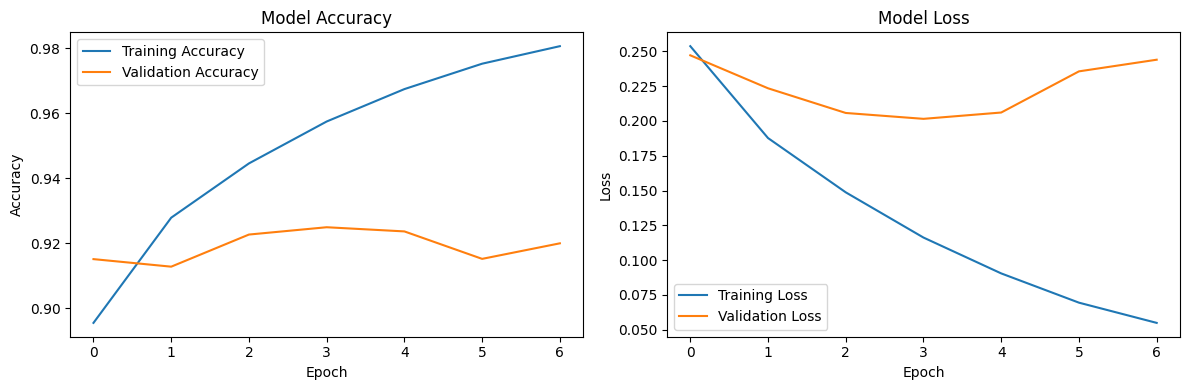

In [62]:
# Строим график обучения
def plot_training_history(history):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

    ax1.plot(history.history['accuracy'], label='Training Accuracy')
    ax1.plot(history.history['val_accuracy'], label='Validation Accuracy')
    ax1.set_title('Model Accuracy')
    ax1.set_xlabel('Epoch')
    ax1.set_ylabel('Accuracy')
    ax1.legend()

    ax2.plot(history.history['loss'], label='Training Loss')
    ax2.plot(history.history['val_loss'], label='Validation Loss')
    ax2.set_title('Model Loss')
    ax2.set_xlabel('Epoch')
    ax2.set_ylabel('Loss')
    ax2.legend()

    plt.tight_layout()
    plt.show()

plot_training_history(history)

Разные способы сохранить нашу модель

In [ ]:
model.save("text_analizer.keras")
model.save_weights("text_analizer.weights.h5")